# 03 — The paper's model, with noise injected in Guppy, agrees with Stim

**Narrative points 3–4.** Can the paper's phenomenological findings be reproduced with
artificial noise injected inside a Guppy program, as a device program would run? Within
the model's constraints (bit-flip data noise, readout that flips only the record), yes.

**Source:** `python -m qec_timing.validation.crosscheck` → `results/crosscheck/crosscheck.json`.
Rotated surface code, Z basis, p = 0.015, λ = 1, b_read = 1, T = 10, the original Stage 4a
grid at d = 5, 7, 9. Both backends' records are decoded by the same PyMatching decoder.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
cc = json.loads((R / "crosscheck" / "crosscheck.json").read_text())
s = cc["summary"]
print(f"{s['points_overlapping']}/{s['points']} points: 99.9% intervals overlap")
for k, v in s.items():
    if isinstance(v, dict):
        print(f"{k:<40} chi2 = {v['chi2']:.1f} on {v['n_points']} (p = {v['chi2_p']:.2f}), "
              f"mean offset {v['mean_z_sigma']:+.1f} sigma")

18/18 points: 99.9% intervals overlap
guppy_vs_stim                            chi2 = 17.1 on 18 (p = 0.51), mean offset -1.9 sigma
stim_vs_original_reference               chi2 = 10.3 on 18 (p = 0.92), mean offset -0.8 sigma
original_guppy_vs_original_reference     chi2 = 22.7 on 18 (p = 0.20), mean offset -0.4 sigma


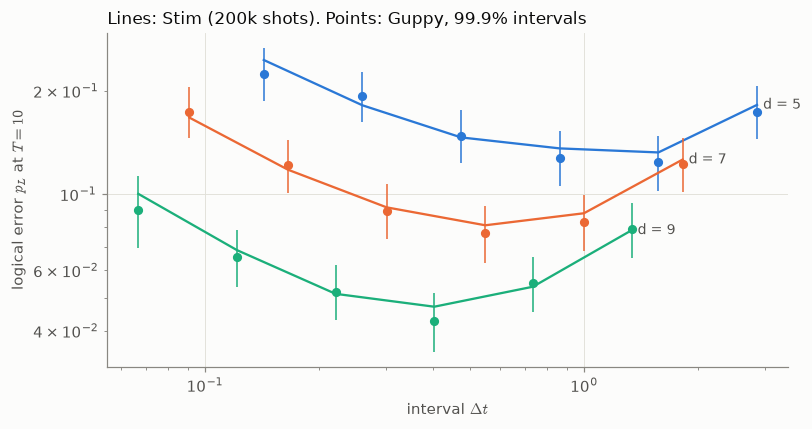

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for d in (5, 7, 9):
    rows = [r for r in cc["rows"] if r["d"] == d]
    dt = np.array([r["dt"] for r in rows])
    st = np.array([r["stim"]["p_L"] for r in rows])
    g = np.array([r["guppy"]["p_L"] for r in rows])
    glo = g - np.array([r["guppy"]["ci"][0] for r in rows]); ghi = np.array([r["guppy"]["ci"][1] for r in rows]) - g
    c = P.SERIES[(5, 7, 9).index(d)]                       # slots 1-3 for this study's distances
    ax.plot(dt, st, "-", color=c, lw=1.5)
    ax.errorbar(dt, g, yerr=[glo, ghi], fmt="o", color=c, ms=5, capsize=0, lw=1)
    P.label_end(ax, dt[-1], st[-1], f"d = {d}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"interval $\Delta t$"); ax.set_ylabel(r"logical error $p_L$ at $T = 10$")
ax.set_title("Lines: Stim (200k shots). Points: Guppy, 99.9% intervals", loc="left")
fig.tight_layout()

**Reading.**
- *Measured:* all 18 points agree within 99.9% intervals; jointly, χ² = 17.1 on 18 (p = 0.51),
  and the mean Guppy–Stim offset is −1.9σ, below any threshold for a real bias. The new Stim
  numbers also reproduce the original repo's reference (p = 0.92).
- *Measured:* each distance shows the U-shape: too-frequent extraction pays p_stab every
  round, too-rare extraction lets idle errors pile up.
- *Method note:* a first run gave Guppy points at the same distance overlapping per-shot seed
  ranges, which correlated them and faked a d = 7 bias; the package now refuses overlapping
  ranges (`spec.overlapping_seed_ranges`). See `results/crosscheck/README.md`.
- *Constraint (narrative point 4):* this model has X-only data noise and ideal gates. It
  validates the injection mechanism and the analysis, not device physics; notebooks 06–08 add
  realistic noise.